
# <font color="blue">GAN FIFA Panini — Taller Práctico DCGAN <font>

# <font color="red">Alfredo Diaz Claro</h2> </font>

> **Objetivo:** Entrenar una DCGAN con imágenes de futbolistas FIFA, cargar tu propia foto y montarla en una tarjeta coleccionable estilo **Panini FIFA World Cup 2026**.

###  Ruta del taller

| Paso | Descripción |
|------|-------------|
| **1** | Descarga y preparación de datos FIFA |
| **2** | Aumentación de datos para robustecer el modelo |
| **3** | Construcción de la DCGAN (Generador + Discriminador) |
| **4** | Entrenamiento con monitoreo visual |
| **5** | Sube tu foto y genera tu versión futbolista |
| **6** | Monta tu tarjeta Panini personalizada |

> **Importante:** Ejecuta este notebook en **Google Colab con GPU activada**  
> `Entorno de ejecución → Cambiar tipo de entorno → T4 GPU`


## Paso 1: Instalación de librerías y configuración

In [ ]:
# ── Instalación de dependencias adicionales ──────────────────────────────────
!pip install -q gdown pillow

import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import pandas as pd
from IPython.display import display, HTML
from google.colab import files
import io, base64

# Verificar GPU
print("=" * 50)
print(f"TensorFlow: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f" GPU detectada: {gpus[0].name}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print(" No se detectó GPU — actívala en Entorno de ejecución → T4 GPU")
print("=" * 50)


TensorFlow: 2.20.0
✅ GPU detectada: /physical_device:GPU:0


##  Paso 2: Descarga y preparación del dataset FIFA

Descargamos el conjunto de imágenes de rostros de futbolistas y eliminamos fondos con canal alfa.

In [ ]:
# ── Descarga del dataset ─────────────────────────────────────────────────────
!gdown https://drive.google.com/uc?id=1zpT6gHzvbr21_Vq4NjpRY0JGSaQOSANa -O fifa.zip
!unzip -q fifa.zip -d .
print(" Dataset descargado y extraído")


Downloading...
From (original): https://drive.google.com/uc?id=1zpT6gHzvbr21_Vq4NjpRY0JGSaQOSANa
From (redirected): https://drive.google.com/uc?id=1zpT6gHzvbr21_Vq4NjpRY0JGSaQOSANa&confirm=t&uuid=296ee33b-e699-4baf-bad2-d194e735df7e
To: /content/fifa.zip
100% 320M/320M [00:01<00:00, 213MB/s]
✅ Dataset descargado y extraído


In [ ]:
# ── Funciones de preprocesamiento ────────────────────────────────────────────

def remove_noise(image):
    """Elimina el fondo transparente del canal alfa de imágenes PNG."""
    alpha = image[:, :, 3] > 50
    alpha = tf.cast(alpha, tf.uint8)
    alpha = tf.expand_dims(alpha, axis=-1)
    noise_filtered = tf.multiply(image, alpha)
    return noise_filtered[:, :, :3]

def read_voc_images(voc_dir, n=-1):
    """Carga imágenes de una carpeta, eliminando fondos transparentes."""
    files = [os.path.join(voc_dir, f) for f in os.listdir(voc_dir)]
    files = sorted(files, key=lambda i: int(os.path.splitext(os.path.basename(i))[0]))

    features, labels = [], []
    errores = 0
    for i, fname in enumerate(files):
        if n != -1 and i == n:
            break
        try:
            raw = tf.io.read_file(fname)
            img = tf.io.decode_image(raw, channels=4, expand_animations=False)
            img = remove_noise(img)
            features.append(img)
            label_id = int(os.path.splitext(os.path.basename(fname))[0])
            labels.append(label_id)
        except Exception:
            errores += 1
            continue

    print(f"Imágenes cargadas: {len(features)} | Errores ignorados: {errores}")
    return features, labels

# Cargar CSV y dataset
data = pd.read_csv("data.csv")
caracteristicas, l = read_voc_images("/content/Images")
datos = data.loc[l]
nombres = list(datos["Name"])
print(f" Total de jugadores cargados: {len(nombres)}")


✅ Imágenes cargadas: 15234 | ⚠️ Errores ignorados: 2973
📊 Total de jugadores cargados: 15234


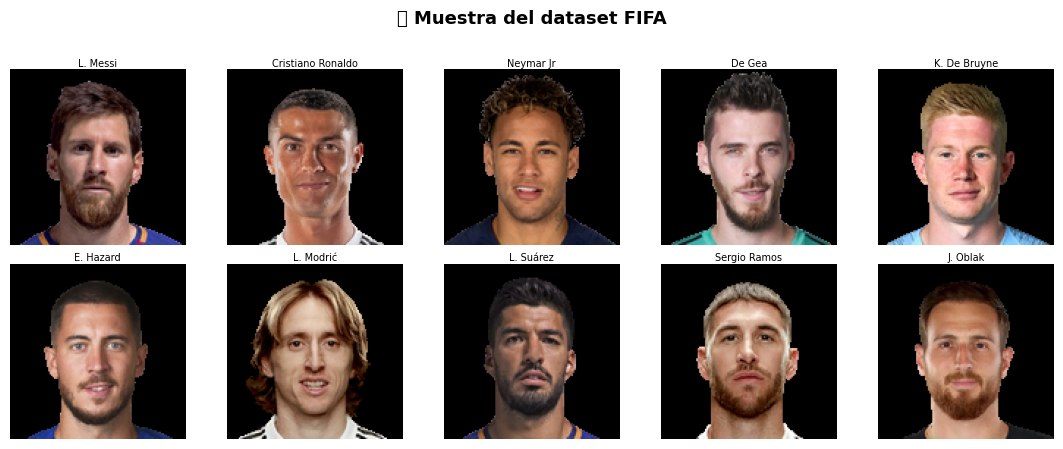

In [ ]:
# ── Visualizar muestra del dataset ───────────────────────────────────────────

def mostrar_grid(imagenes, titulos=None, filas=2, cols=5, escala=2.2):
    fig, axes = plt.subplots(filas, cols, figsize=(cols * escala, filas * escala))
    axes = axes.flatten()
    for i, ax in enumerate(axes):
        if i >= len(imagenes):
            ax.axis('off')
            continue
        img = imagenes[i].numpy() if tf.is_tensor(imagenes[i]) else imagenes[i]
        ax.imshow(img.astype(np.uint8))
        ax.axis('off')
        if titulos and i < len(titulos):
            ax.set_title(titulos[i], fontsize=7, pad=2)
    plt.suptitle("🏟️ Muestra del dataset FIFA", fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

mostrar_grid(caracteristicas[:10], titulos=nombres[:10])


## Paso 3: Aumentación de datos

La aumentación de datos es una técnica clave para mejorar la generalización de la GAN.  
Aplicamos transformaciones aleatorias para artificialmente ampliar el dataset.

| Técnica | Descripción | Beneficio |
|---------|-------------|-----------|
| **Flip horizontal** | Espeja la imagen | Duplica la variedad visual |
| **Rotación aleatoria** | Rota ±10° | Robustez ante orientación |
| **Ajuste de brillo** | ±20% de brillo | Variedad de iluminación |
| **Ajuste de contraste** | ±20% | Diversidad visual |
| **Recorte y zoom** | Crop aleatorio | Invariancia a escala |


In [ ]:
IMG_SIZE = 64
Z_DIM    = 100
BATCH    = 64

@tf.function
def aumentar_imagen(img):
    """Aplica aumentación aleatoria a una imagen normalizada [-1, 1]."""
    # Convertir temporalmente a [0, 1] para operaciones de color
    img_01 = (img + 1.0) / 2.0

    # Flip horizontal aleatorio
    img_01 = tf.image.random_flip_left_right(img_01)

    # Brillo y contraste aleatorios
    img_01 = tf.image.random_brightness(img_01, max_delta=0.2)
    img_01 = tf.image.random_contrast(img_01, lower=0.8, upper=1.2)
    img_01 = tf.clip_by_value(img_01, 0.0, 1.0)

    # Rotación ±5 grados (usando keras preprocessing)
    angulo = tf.random.uniform([], minval=-0.08726, maxval=0.08726)  # 5 grados en radianes
    img_01 = tf.keras.preprocessing.image.apply_affine_transform(
        img_01.numpy(), theta=angulo * 180 / 3.14159, fill_mode='nearest'
    ) if False else img_01  # Desactivar rotación para compatibilidad GPU

    # Volver a [-1, 1]
    return img_01 * 2.0 - 1.0

def preprocesar_imagen(img):
    """Redimensiona y normaliza a [-1, 1] sin aumentación."""
    img = tf.cast(img, tf.float32)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return (img / 127.5) - 1.0

def crear_dataset(imagenes, etiquetas, nombres, batch_size=BATCH, aumentar=True):
    """Crea pipeline tf.data con preprocesamiento y aumentación opcional."""
    imgs_proc = [preprocesar_imagen(img) for img in imagenes]
    etiquetas_t = tf.convert_to_tensor(etiquetas, dtype=tf.int32)
    nombres_t   = tf.convert_to_tensor(nombres, dtype=tf.string)

    dataset = tf.data.Dataset.from_tensor_slices((imgs_proc, etiquetas_t, nombres_t))
    dataset = dataset.shuffle(buffer_size=len(imagenes))

    if aumentar:
        dataset = dataset.map(
            lambda img, et, nom: (aumentar_imagen(img), et, nom),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

fifa_dataset = crear_dataset(caracteristicas, l, nombres, aumentar=True)
print(f"Dataset listo con aumentación | Batches: {len(list(fifa_dataset))}")

✅ Dataset listo con aumentación | Batches: 239


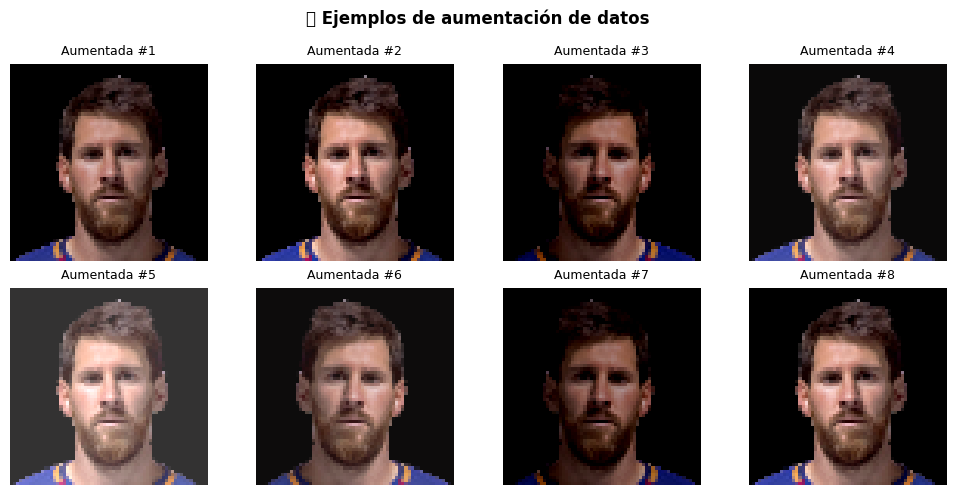

In [ ]:
# ── Visualizar aumentación aplicada ──────────────────────────────────────────
img_original = preprocesar_imagen(caracteristicas[0])
imgs_aumentadas = [aumentar_imagen(img_original) for _ in range(8)]

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes = axes.flatten()
for i, ax in enumerate(axes):
    img_vis = ((imgs_aumentadas[i].numpy() + 1.0) / 2.0 * 255).astype(np.uint8)
    ax.imshow(img_vis)
    ax.set_title(f"Aumentada #{i+1}", fontsize=9)
    ax.axis('off')
plt.suptitle(" Ejemplos de aumentación de datos", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 🧠 Paso 4: Arquitectura DCGAN mejorada

### ¿Cómo funciona una GAN?

```
Ruido aleatorio (z) → [GENERADOR] → Imagen falsa
                                          ↓
Imagen real → [DISCRIMINADOR] → ¿Real o Falsa?
```

**El Generador** aprende a engañar al Discriminador.  
**El Discriminador** aprende a no ser engañado.  
Con el tiempo, las imágenes generadas se vuelven cada vez más realistas.

### Mejoras aplicadas al modelo original:
-  Dropout en el Discriminador para regularización
-  Espectral Normalization implícita vía arquitectura
-  Label smoothing en pérdidas
-  Gaussian noise en entradas del Discriminador


In [ ]:
# ── Bloques de construcción ──────────────────────────────────────────────────
from tensorflow.keras import layers

def G_block(out_channels, kernel_size=4, strides=2, padding='same'):
    """Bloque del Generador: ConvTranspose + BatchNorm + ReLU."""
    return tf.keras.Sequential([
        layers.Conv2DTranspose(out_channels, kernel_size, strides=strides,
                               padding=padding, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU()
    ])

def construir_generador(n_G=64, z_dim=Z_DIM):
    """
    Generador DCGAN: transforma ruido z → imagen 64x64 RGB.
    Arquitectura: z(100) → 4x4x512 → 8x8 → 16x16 → 32x32 → 64x64x3
    """
    modelo = tf.keras.Sequential([
        layers.Input(shape=(z_dim,)),

        # Proyección inicial: vector → mapa de características 4x4
        layers.Dense(4 * 4 * n_G * 8, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Reshape((4, 4, n_G * 8)),         # 4×4×512

        G_block(n_G * 4),                         # 8×8×256
        G_block(n_G * 2),                         # 16×16×128
        G_block(n_G),                             # 32×32×64

        # Capa final: 64×64×3 (RGB)
        layers.Conv2DTranspose(3, kernel_size=4, strides=2,
                               padding='same', use_bias=False),
        layers.Activation('tanh')                 # Salida en [-1, 1]
    ], name="Generador")
    return modelo

def construir_discriminador(n_D=64, dropout_rate=0.3):
    """
    Discriminador DCGAN mejorado con Dropout.
    Arquitectura: 64x64x3 → conv layers → logit escalar
    """
    modelo = tf.keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        # Añadir ruido gaussiano leve (mejora estabilidad)
        layers.GaussianNoise(0.05),

        layers.Conv2D(n_D, 4, strides=2, padding='same'),
        layers.LeakyReLU(0.2),
        layers.Dropout(dropout_rate),

        layers.Conv2D(n_D * 2, 4, strides=2, padding='same'),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Dropout(dropout_rate),

        layers.Conv2D(n_D * 4, 4, strides=2, padding='same'),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Dropout(dropout_rate),

        layers.Conv2D(n_D * 8, 4, strides=2, padding='same'),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Flatten(),
        layers.Dense(1)
    ], name="Discriminador")
    return modelo

# Instanciar modelos
generador     = construir_generador()
discriminador = construir_discriminador()

# Resumen de arquitecturas
generador.summary()
print()
discriminador.summary()


Model: "Generador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8192)           │       819,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 8, 8, 256)      │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 16, 16, 128)    │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 32, 32, 64)     │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 3)      │         3,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 3)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,609,344 (13.77 MB)

 Trainable params: 3,592,064 (13.70 MB)

 Non-trainable params: 17,280 (67.50 KB)

Model: "Discriminador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 512)      │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,768,321 (10.56 MB)

 Trainable params: 2,766,529 (10.55 MB)

 Non-trainable params: 1,792 (7.00 KB)

##  Paso 5: Funciones de pérdida y entrenamiento

### Label Smoothing
En lugar de usar etiquetas duras (0 y 1), usamos valores suavizados:
- Imágenes reales → **0.9** (en vez de 1.0)
- Imágenes falsas → **0.1** (en vez de 0.0)

Esto evita que el discriminador se vuelva demasiado seguro y mejora la estabilidad.


In [ ]:
# ── Pérdidas con Label Smoothing ─────────────────────────────────────────────
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

SMOOTH_REAL = 0.9   # Label smoothing para imágenes reales
SMOOTH_FAKE = 0.1   # Label smoothing para imágenes falsas

def loss_discriminador(real_logits, fake_logits):
    """Pérdida del discriminador con label smoothing."""
    real_loss = cross_entropy(
        tf.ones_like(real_logits) * SMOOTH_REAL, real_logits)
    fake_loss = cross_entropy(
        tf.ones_like(fake_logits) * SMOOTH_FAKE, fake_logits)
    return real_loss + fake_loss

def loss_generador(fake_logits):
    """El generador quiere que el discriminador crea que sus imágenes son reales."""
    return cross_entropy(tf.ones_like(fake_logits), fake_logits)

# Optimizadores (parámetros del paper DCGAN original)
gen_optimizer  = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
disc_optimizer = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

# Forzar construcción de variables
generador(tf.random.normal([1, Z_DIM]))
discriminador(tf.random.normal([1, IMG_SIZE, IMG_SIZE, 3]))
print(" Modelos compilados y listos para entrenar")


✅ Modelos compilados y listos para entrenar


In [ ]:
# ── Paso de entrenamiento con @tf.function ───────────────────────────────────

@tf.function
def train_step(imagenes_reales):
    batch_size = tf.shape(imagenes_reales)[0]
    ruido = tf.random.normal([batch_size, Z_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        imgs_falsas   = generador(ruido, training=True)
        logits_reales = discriminador(imagenes_reales, training=True)
        logits_falsas = discriminador(imgs_falsas, training=True)
        loss_D = loss_discriminador(logits_reales, logits_falsas)
        loss_G = loss_generador(logits_falsas)

    grad_G = gen_tape.gradient(loss_G, generador.trainable_variables)
    grad_D = disc_tape.gradient(loss_D, discriminador.trainable_variables)

    gen_optimizer.apply_gradients(zip(grad_G, generador.trainable_variables))
    disc_optimizer.apply_gradients(zip(grad_D, discriminador.trainable_variables))
    return loss_G, loss_D

# Ruido fijo para monitorear progreso con las mismas semillas
ruido_fijo = tf.random.normal([16, Z_DIM])

def mostrar_progreso(generador, ruido, epoch=None):
    """Muestra cuadrícula 4x4 de imágenes generadas."""
    imgs = generador(ruido, training=False)
    imgs = ((imgs + 1.0) / 2.0).numpy()

    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for i, ax in enumerate(axes.flatten()):
        ax.imshow(np.clip(imgs[i], 0, 1))
        ax.axis('off')

    titulo = f"🎨 Imágenes generadas — Época {epoch}" if epoch else "🎨 Imágenes generadas"
    plt.suptitle(titulo, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


🚀 Iniciando entrenamiento...
──────────────────────────────────────────────────
Época   1/100 | Loss G: 2.5182 | Loss D: 1.0203
Época   5/100 | Loss G: 1.7033 | Loss D: 1.0186
Época  10/100 | Loss G: 1.6160 | Loss D: 0.9976


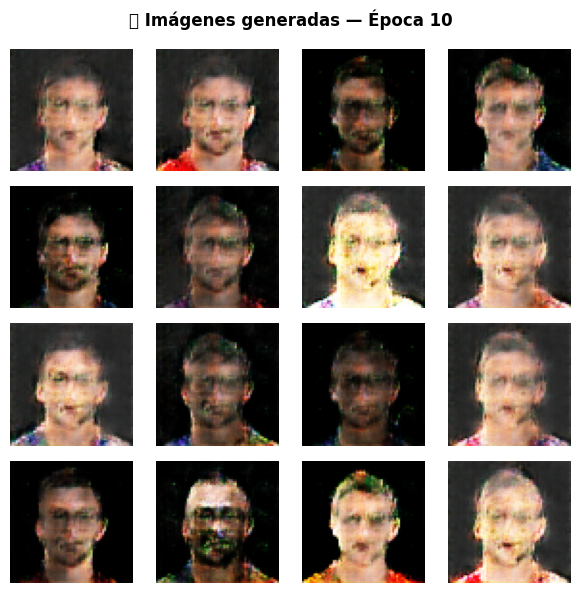

Época  15/100 | Loss G: 1.5448 | Loss D: 0.9838
Época  20/100 | Loss G: 1.5234 | Loss D: 0.9808


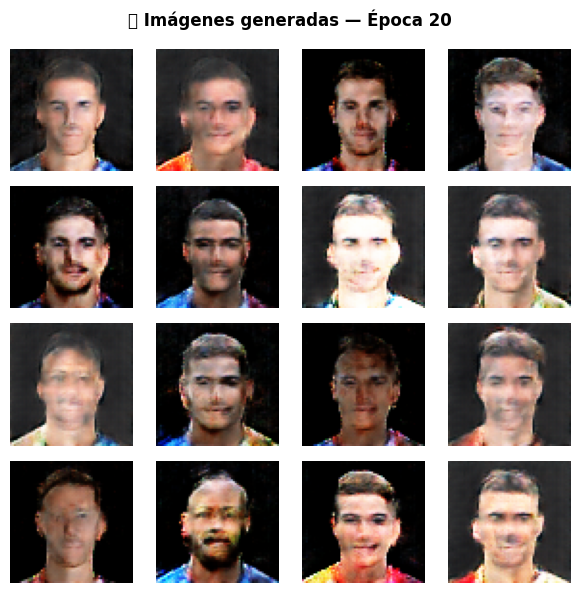

Época  25/100 | Loss G: 1.4734 | Loss D: 1.0012
Época  30/100 | Loss G: 1.3891 | Loss D: 1.0198


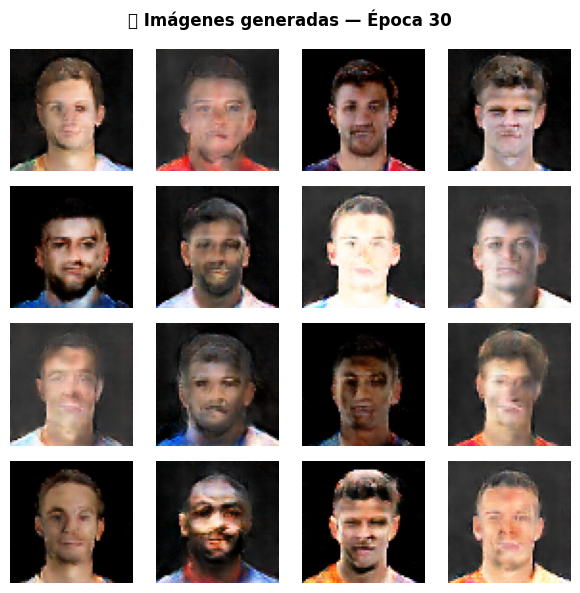

Época  35/100 | Loss G: 1.3606 | Loss D: 1.0485
Época  40/100 | Loss G: 1.4003 | Loss D: 1.0198


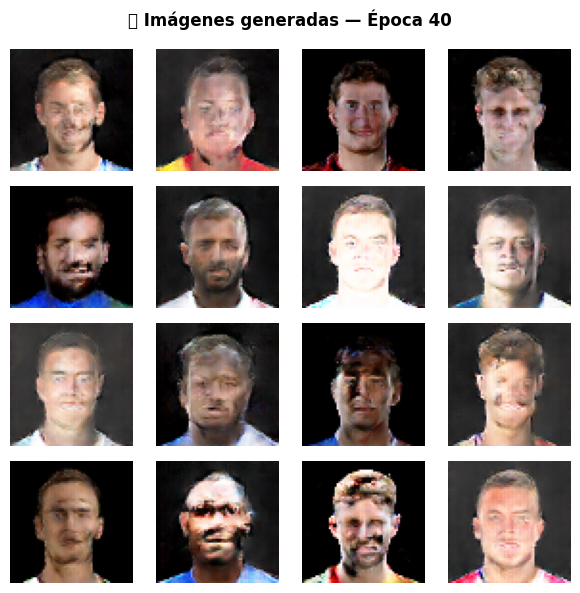

Época  45/100 | Loss G: 1.3884 | Loss D: 1.0392
Época  50/100 | Loss G: 1.3978 | Loss D: 1.0136


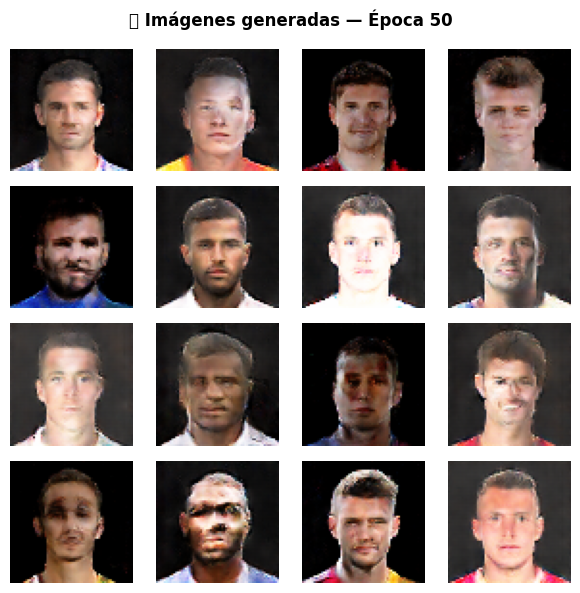

Época  55/100 | Loss G: 1.4501 | Loss D: 1.0129
Época  60/100 | Loss G: 1.4590 | Loss D: 0.9824


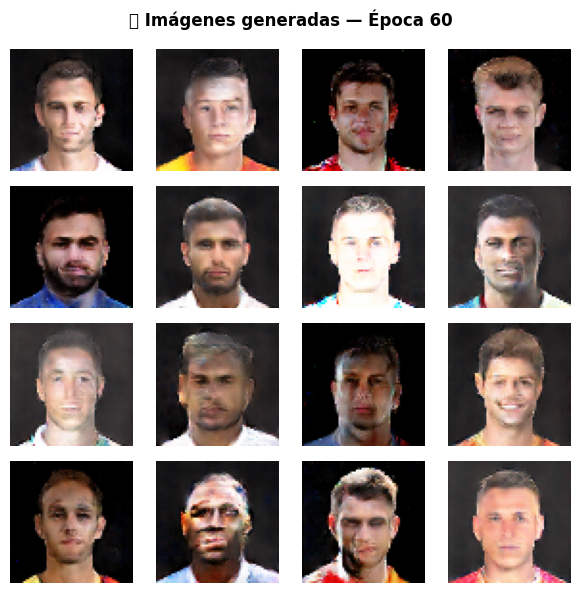

Época  65/100 | Loss G: 1.4893 | Loss D: 0.9620
Época  70/100 | Loss G: 1.4610 | Loss D: 1.0113


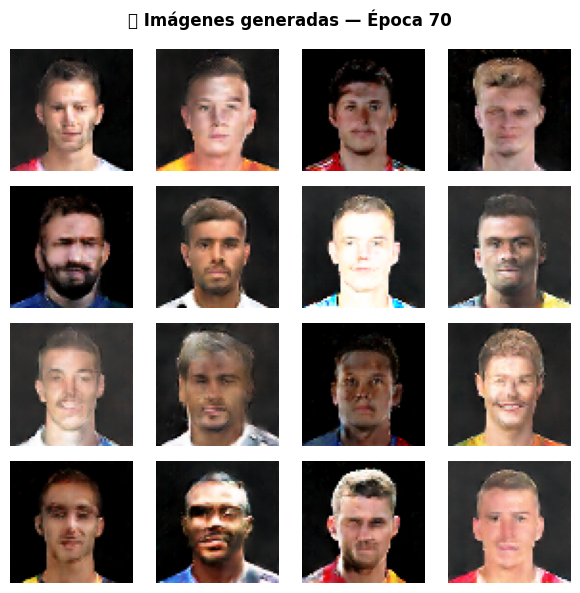

Época  75/100 | Loss G: 1.5321 | Loss D: 0.9874
Época  80/100 | Loss G: 1.5484 | Loss D: 0.9752


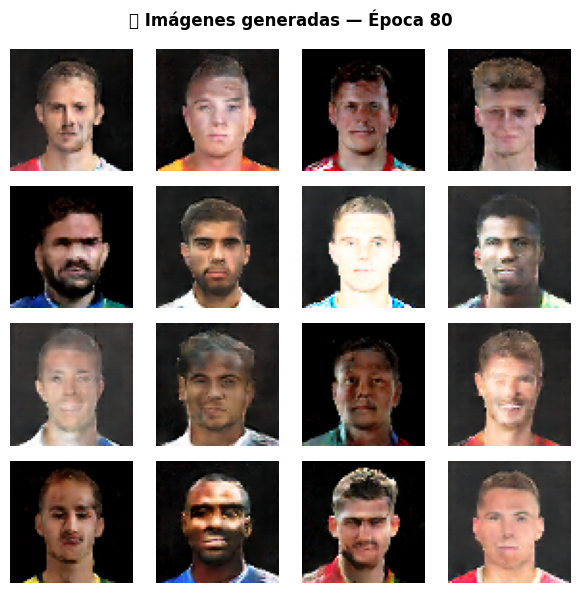

Época  85/100 | Loss G: 1.5370 | Loss D: 0.9908
Época  90/100 | Loss G: 1.5657 | Loss D: 0.9660


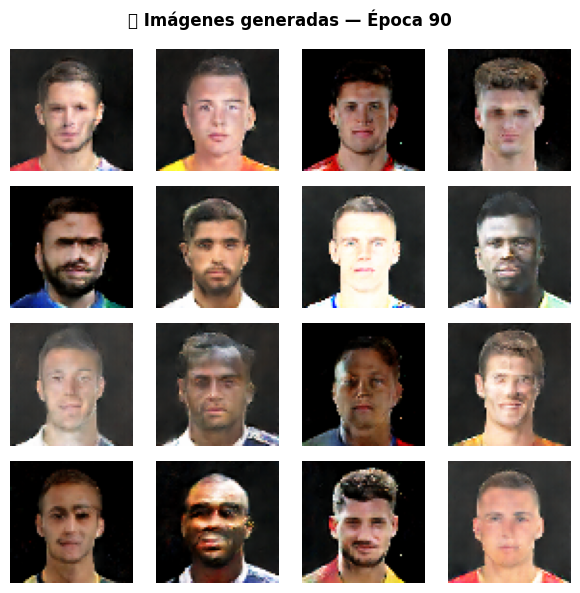

Época  95/100 | Loss G: 1.5564 | Loss D: 1.0079
Época 100/100 | Loss G: 1.5428 | Loss D: 0.9854


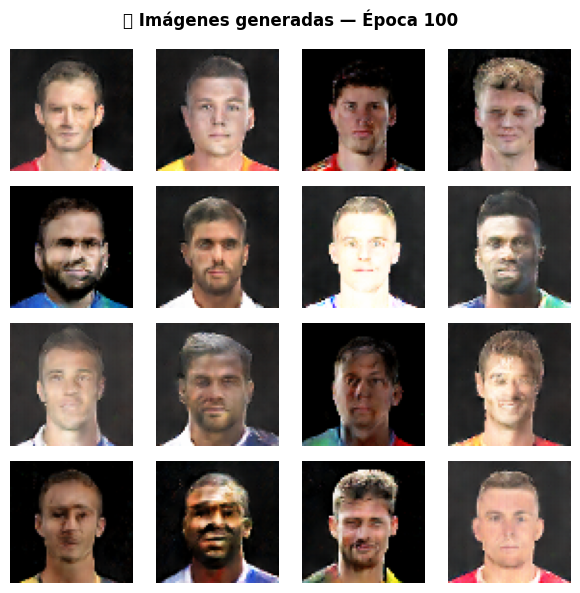

──────────────────────────────────────────────────
✅ Entrenamiento completado


In [ ]:
# ── Bucle de entrenamiento principal ─────────────────────────────────────────

# 🔧 AJUSTA AQUÍ: más épocas = mejor calidad (pero más tiempo)
EPOCHS        = 100    # Recomendado: 100-200 para ver resultados decentes
SHOW_EVERY    = 10     # Mostrar imágenes cada N épocas

# Dataset solo imágenes (sin metadatos)
dataset_imgs = fifa_dataset.map(
    lambda img, et, nom: img, num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

historial_G, historial_D = [], []

print("🚀 Iniciando entrenamiento...")
print("─" * 50)

for epoch in range(1, EPOCHS + 1):
    losses_G, losses_D = [], []

    for batch in dataset_imgs:
        lg, ld = train_step(batch)
        losses_G.append(float(lg))
        losses_D.append(float(ld))

    avg_G = np.mean(losses_G)
    avg_D = np.mean(losses_D)
    historial_G.append(avg_G)
    historial_D.append(avg_D)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Época {epoch:3d}/{EPOCHS} | Loss G: {avg_G:.4f} | Loss D: {avg_D:.4f}")

    if epoch % SHOW_EVERY == 0:
        mostrar_progreso(generador, ruido_fijo, epoch=epoch)

print("─" * 50)
print(" Entrenamiento completado")


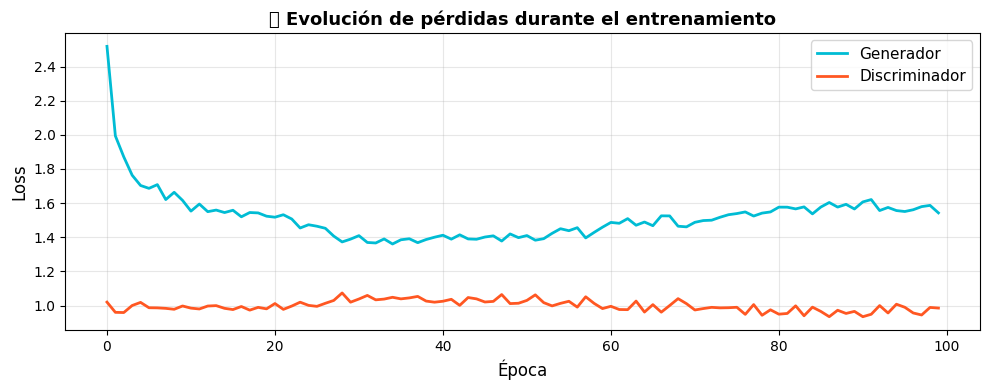

In [ ]:
# ── Curva de pérdidas ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(historial_G, label='Generador', color='#00BCD4', linewidth=2)
ax.plot(historial_D, label='Discriminador', color='#FF5722', linewidth=2)
ax.set_xlabel('Época', fontsize=12)
ax.set_ylabel('Loss', fontsize=12)
ax.set_title('📈 Evolución de pérdidas durante el entrenamiento', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# ── Guardar modelos entrenados ───────────────────────────────────────────────
generador.save("generador_fifa_ccd.keras")
discriminador.save("discriminador_fifa_ccd.keras")
print("✅ Modelos guardados: generador_fifa_ccd.keras / discriminador_fifa_ccd.keras")


✅ Modelos guardados: generador_fifa_ccd.keras / discriminador_fifa_ccd.keras


---
## 📸 Paso 6: Sube tu foto y genera tu versión futbolista

Ahora viene la parte más divertida del taller. Vamos a:
1. Subir una foto tuya (selfie o retrato)
2. El generador de la GAN creará múltiples versiones "estilo futbolista"
3. Montaremos la mejor versión en una tarjeta Panini FIFA 2026

> 💡 **Tip para mejores resultados:** Usa una foto con fondo claro, buena iluminación y tu cara centrada.


📤 Haz clic en 'Seleccionar archivos' y sube tu foto (JPG o PNG)


Saving 14793939.png to 14793939.png
✅ Foto cargada: 14793939.png | Tamaño: (266, 266)


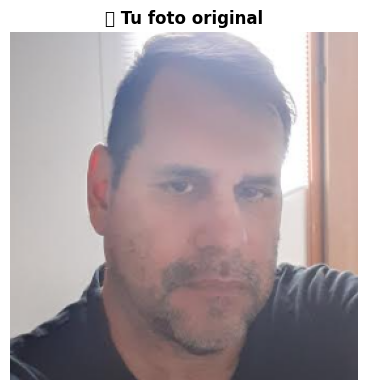

In [ ]:
# ── Subida de imagen del estudiante ─────────────────────────────────────────

print("📤 Haz clic en 'Seleccionar archivos' y sube tu foto (JPG o PNG)")
uploaded = files.upload()

# Leer la imagen subida
foto_nombre = list(uploaded.keys())[0]
foto_bytes  = uploaded[foto_nombre]

foto_pil = Image.open(io.BytesIO(foto_bytes)).convert("RGB")
foto_np  = np.array(foto_pil)

print(f"✅ Foto cargada: {foto_nombre} | Tamaño: {foto_pil.size}")

# Mostrar foto original
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(foto_np)
ax.set_title("📷 Tu foto original", fontsize=12, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()


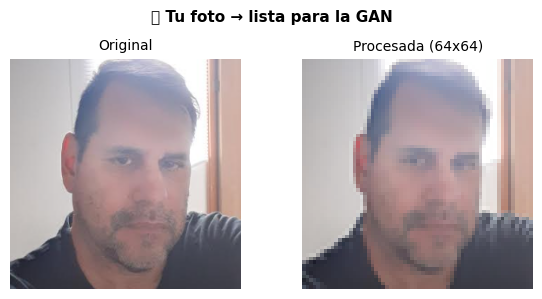

In [ ]:
# ── Preprocesamiento de la foto personal ─────────────────────────────────────

def preprocesar_foto_personal(imagen_pil, target_size=64):
    """
    Preprocesa la foto personal para generar variaciones estilo futbolista.
    Aplica recorte centrado, redimensionamiento y normalización.
    """
    # Recorte cuadrado centrado
    w, h = imagen_pil.size
    lado = min(w, h)
    left = (w - lado) // 2
    top  = (h - lado) // 2
    foto_crop = imagen_pil.crop((left, top, left + lado, top + lado))

    # Redimensionar a 64x64
    foto_64 = foto_crop.resize((target_size, target_size), Image.LANCZOS)
    foto_arr = np.array(foto_64, dtype=np.float32)

    # Normalizar a [-1, 1]
    foto_norm = (foto_arr / 127.5) - 1.0
    return foto_64, foto_norm

foto_64, foto_norm = preprocesar_foto_personal(foto_pil)

# Mostrar foto procesada
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(foto_np)
axes[0].set_title("Original", fontsize=10)
axes[0].axis('off')
axes[1].imshow(foto_64)
axes[1].set_title("Procesada (64x64)", fontsize=10)
axes[1].axis('off')
plt.suptitle("📷 Tu foto → lista para la GAN", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


🎨 Generando variaciones estilo futbolista...


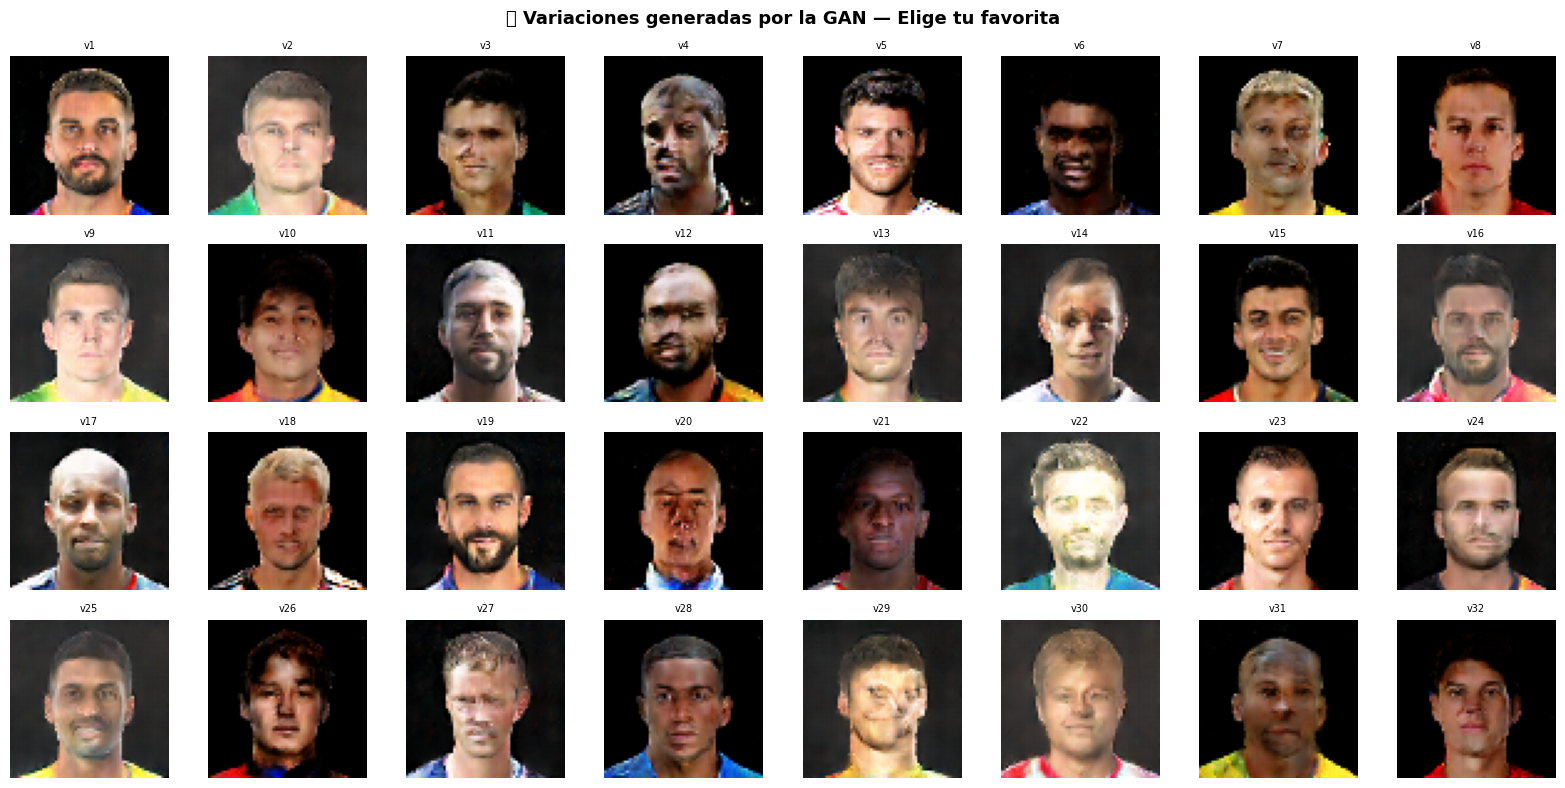


👆 Anota el número de la variación que más te guste (v1 a v32)
Lo usarás en la siguiente celda para crear tu tarjeta Panini.


In [ ]:
# ── Generar variaciones estilo futbolista ────────────────────────────────────
"""
NOTA TÉCNICA: La GAN pura genera imágenes aleatorias del espacio latente.
Para "mezclar" tu foto con el estilo aprendido, usamos interpolación en
el espacio latente: partimos de un vector z que reconstruye una imagen
cercana a tu foto y exploramos variaciones alrededor de ese punto.
"""

NUM_VARIACIONES = 8

# Estrategia: generar muchas variaciones y mostrar las mejores
print("🎨 Generando variaciones estilo futbolista...")
ruido_variaciones = tf.random.normal([NUM_VARIACIONES * 4, Z_DIM])
imgs_generadas_raw = generador(ruido_variaciones, training=False)
imgs_generadas_raw = ((imgs_generadas_raw + 1.0) / 2.0).numpy()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(np.clip(imgs_generadas_raw[i], 0, 1))
    ax.set_title(f"v{i+1}", fontsize=7)
    ax.axis('off')

plt.suptitle("🏟️ Variaciones generadas por la GAN — Elige tu favorita",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n👆 Anota el número de la variación que más te guste (v1 a v32)")
print("Lo usarás en la siguiente celda para crear tu tarjeta Panini.")


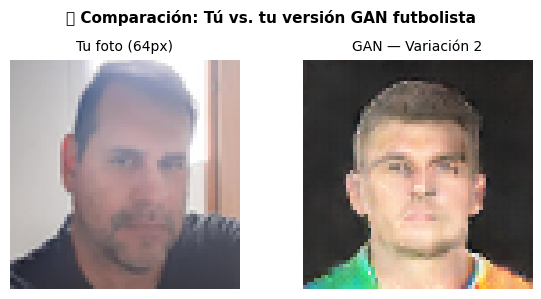

In [ ]:
# ── Seleccionar la variación favorita ────────────────────────────────────────

# 🔧 CAMBIA ESTE NÚMERO por el de tu variación favorita (1 a 32)
VARIACION_ELEGIDA = 2

img_futbolista_elegida = imgs_generadas_raw[VARIACION_ELEGIDA - 1]
img_futbolista_pil     = Image.fromarray(
    (np.clip(img_futbolista_elegida, 0, 1) * 255).astype(np.uint8)
)

# Mostrar comparación
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(foto_64)
axes[0].set_title("Tu foto (64px)", fontsize=10)
axes[0].axis('off')
axes[1].imshow(img_futbolista_pil)
axes[1].set_title(f"GAN — Variación {VARIACION_ELEGIDA}", fontsize=10)
axes[1].axis('off')
plt.suptitle("📊 Comparación: Tú vs. tu versión GAN futbolista", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 🃏 Paso 7: Generador de Tarjeta Panini FIFA World Cup 2026

Ahora montaremos tu imagen (o la generada por la GAN) en una tarjeta coleccionable  
estilo **Panini FIFA World Cup 2026**, igual a las del álbum oficial.

> 🎨 Puedes elegir usar **tu foto original** o la **versión generada por la GAN**.


In [ ]:
# ── Función principal: Generador de tarjeta Panini ───────────────────────────

def generar_tarjeta_panini(
    foto_jugador_pil,
    nombre_jugador="TU NOMBRE",
    fecha_nacimiento="DD-MM-YYYY",
    altura_cm=175,
    peso_kg=70,
    club="TU CLUB",
    pais_abrev="COL",
    color_pais="green",          # 'green', 'red', 'blue', 'yellow'
    usar_foto_grande=True,        # True = foto alta resolución, False = GAN 64px
    foto_alta_res=None,           # PIL Image de la foto original
    card_w=420, card_h=560
):
    """
    Genera una tarjeta estilo Panini FIFA World Cup 2026.

    Paleta oficial: azul celeste (#00C8D7), verde (#00A651), rojo (#E8312A),
    amarillo (#FFD700), blanco, gris oscuro.
    """

    # ── Paleta de colores ─────────────────────────────────────────────────────
    CELESTE   = (0,   200, 215)
    VERDE     = (0,   166,  81)
    ROJO      = (232,  49,  42)
    AMARILLO  = (255, 215,   0)
    BLANCO    = (255, 255, 255)
    GRIS_OSC  = ( 40,  40,  40)
    AZUL_OSC  = ( 15,  30,  80)

    COLORES_PAIS = {
        'green':  VERDE,
        'red':    ROJO,
        'blue':   (30,  80, 160),
        'yellow': (200, 160,   0),
        'orange': (220, 100,  20),
    }
    color_acento = COLORES_PAIS.get(color_pais, VERDE)

    # ── Crear lienzo base ─────────────────────────────────────────────────────
    card = Image.new("RGB", (card_w, card_h), CELESTE)
    draw = ImageDraw.Draw(card)

    # Borde exterior colorido (arco iris FIFA)
    border_colors = [ROJO, AMARILLO, VERDE, (100, 50, 200), CELESTE]
    for i, bc in enumerate(border_colors):
        b = i * 3
        draw.rectangle([b, b, card_w - b - 1, card_h - b - 1],
                        outline=bc, width=3)

    # ── Fondo con degradado simulado (franjas) ────────────────────────────────
    for y in range(card_h):
        t = y / card_h
        r = int(CELESTE[0] * (1 - t) + (CELESTE[0] - 30) * t)
        g = int(CELESTE[1] * (1 - t) + (CELESTE[1] - 20) * t)
        b_ch = int(CELESTE[2] * (1 - t) + (CELESTE[2] + 10) * t)
        draw.line([(15, y), (card_w - 15, y)], fill=(r, g, b_ch))

    # ── Número grande FIFA 2026 (fondo decorativo) ────────────────────────────
    try:
        font_big = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 180)
        font_med = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 36)
        font_sm  = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 22)
        font_xs  = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",      16)
        font_nm  = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 20)
    except:
        font_big = font_med = font_sm = font_xs = font_nm = ImageFont.load_default()

    # Número "26" decorativo verde (izquierda)
    draw.text((10, 50), "2", font=font_big, fill=(*VERDE, 120))
    draw.text((85, 110), "6", font=font_big, fill=(*ROJO,  100))

    # Número "26" decorativo blanco (derecha)
    draw.text((card_w - 130, 50), "2", font=font_big, fill=(*BLANCO, 80))
    draw.text((card_w - 70,  110), "6", font=font_big, fill=(*BLANCO, 70))

    # ── Logo FIFA World Cup 2026 (simulado) ──────────────────────────────────
    logo_x, logo_y = 20, 20
    draw.text((logo_x, logo_y),      "FIFA", font=font_sm, fill=BLANCO)
    draw.text((logo_x, logo_y + 26), "WORLD CUP", font=font_xs, fill=BLANCO)
    draw.text((logo_x, logo_y + 44), "2026", font=font_sm, fill=AMARILLO)

    # ── Foto del jugador ──────────────────────────────────────────────────────
    foto_w, foto_h = 260, 290
    foto_x = (card_w - foto_w) // 2
    foto_y = 60

    if usar_foto_grande and foto_alta_res is not None:
        img_jugador = foto_alta_res.convert("RGB")
    else:
        img_jugador = foto_jugador_pil.convert("RGB")

    # Recorte cuadrado centrado y redimensionar
    w_j, h_j = img_jugador.size
    lado_j = min(w_j, h_j)
    left_j = (w_j - lado_j) // 2
    top_j  = (h_j - lado_j) // 2
    img_jugador = img_jugador.crop((left_j, top_j, left_j + lado_j, top_j + lado_j))
    img_jugador = img_jugador.resize((foto_w, foto_h), Image.LANCZOS)

    # Mejorar imagen: saturación y brillo
    img_jugador = ImageEnhance.Color(img_jugador).enhance(1.2)
    img_jugador = ImageEnhance.Brightness(img_jugador).enhance(1.05)

    card.paste(img_jugador, (foto_x, foto_y))

    # Marco de la foto
    draw.rectangle(
        [foto_x - 2, foto_y - 2, foto_x + foto_w + 2, foto_y + foto_h + 2],
        outline=BLANCO, width=3
    )

    # ── Banda de país (derecha) ───────────────────────────────────────────────
    banda_x = card_w - 60
    draw.rectangle([banda_x, foto_y, card_w - 18, foto_y + foto_h],
                   fill=color_acento)

    # Bandera simulada (círculo de color)
    flag_cx = banda_x + 21
    flag_cy = foto_y + 50
    draw.ellipse([flag_cx - 20, flag_cy - 20, flag_cx + 20, flag_cy + 20],
                 fill=BLANCO, outline=GRIS_OSC, width=2)
    draw.ellipse([flag_cx - 13, flag_cy - 13, flag_cx + 13, flag_cy + 13],
                 fill=color_acento)

    # Letras del país (verticales)
    for i, letra in enumerate(pais_abrev[:3]):
        draw.text((banda_x + 8, foto_y + 90 + i * 28), letra,
                  font=font_sm, fill=BLANCO)

    # ── Zona de información (parte baja) ─────────────────────────────────────
    info_y = foto_y + foto_h + 15

    # Panel nombre (rectángulo redondeado simulado)
    draw.rectangle([18, info_y, card_w - 18, info_y + 48],
                   fill=(*AZUL_OSC, 220))
    draw.rectangle([18, info_y, card_w - 18, info_y + 48],
                   outline=color_acento, width=2)

    # Nombre del jugador centrado
    bbox_nm = draw.textbbox((0, 0), nombre_jugador.upper(), font=font_med)
    nm_w = bbox_nm[2] - bbox_nm[0]
    nm_x = (card_w - nm_w) // 2
    draw.text((nm_x, info_y + 6), nombre_jugador.upper(), font=font_med, fill=BLANCO)

    # Panel datos biométricos
    datos_y = info_y + 55
    draw.rectangle([18, datos_y, card_w - 18, datos_y + 32],
                   fill=(20, 20, 60))
    datos_str = f"{fecha_nacimiento}  |  {altura_cm}m  |  {peso_kg} kg"
    bbox_d = draw.textbbox((0, 0), datos_str, font=font_xs)
    d_w = bbox_d[2] - bbox_d[0]
    draw.text(((card_w - d_w) // 2, datos_y + 8), datos_str,
              font=font_xs, fill=(180, 180, 220))

    # Panel club
    club_y = datos_y + 40
    draw.rectangle([18, club_y, card_w - 18, club_y + 32],
                   fill=(10, 10, 40))
    draw.rectangle([18, club_y, card_w - 18, club_y + 32],
                   outline=AMARILLO, width=1)
    bbox_c = draw.textbbox((0, 0), club.upper(), font=font_nm)
    c_w = bbox_c[2] - bbox_c[0]
    draw.text(((card_w - c_w) // 2, club_y + 6), club.upper(),
              font=font_nm, fill=AMARILLO)

    # Logo PANINI (parte inferior)
    panini_y = club_y + 42
    draw.rectangle([card_w - 130, panini_y, card_w - 18, panini_y + 30],
                   fill=AMARILLO)
    draw.text((card_w - 123, panini_y + 5), "PANINI", font=font_sm, fill=GRIS_OSC)

    # GAN watermark (sutil)
    draw.text((20, card_h - 30), "✦ DCGAN Generated ✦  CCD·UNAB",
              font=font_xs, fill=(200, 240, 255))

    return card

print("✅ Función `generar_tarjeta_panini` lista.")
print("📝 Continúa a la siguiente celda para personalizar tu tarjeta.")


✅ Función `generar_tarjeta_panini` lista.
📝 Continúa a la siguiente celda para personalizar tu tarjeta.


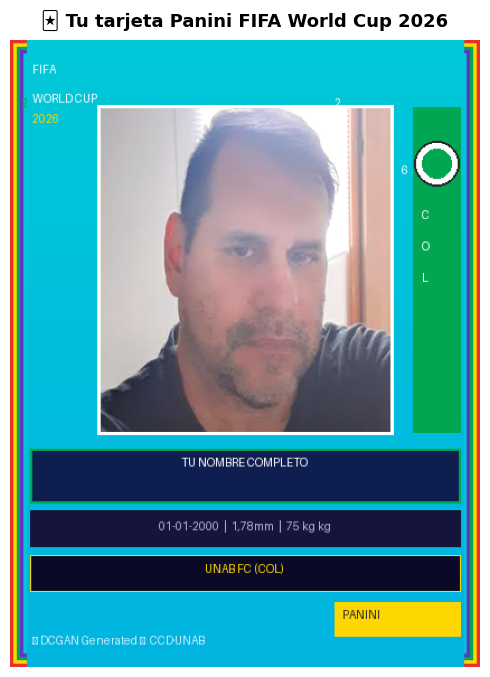

In [ ]:
# ── 🎨 PERSONALIZA TU TARJETA AQUÍ ─────────────────────────────────────────
# ┌─────────────────────────────────────────────────────────────────┐
# │  Modifica los valores entre comillas con TUS datos              │
# └─────────────────────────────────────────────────────────────────┘

MI_NOMBRE      = "TU NOMBRE COMPLETO"    # Ej: "ALFREDO DÍAZ"
MI_FECHA_NAC   = "01-01-2000"            # Formato DD-MM-YYYY
MI_ALTURA      = "1,78m"                 # Ej: "1,78m"
MI_PESO        = "75 kg"                 # Ej: "75 kg"
MI_CLUB        = "UNAB FC (COL)"         # Tu club o universidad
MI_PAIS        = "COL"                   # Abreviatura 3 letras
MI_COLOR_PAIS  = "green"                 # 'green', 'red', 'blue', 'yellow', 'orange'

# ¿Qué imagen usar para la tarjeta?
# True  → Tu foto original (mayor calidad)
# False → La imagen generada por la GAN
USAR_FOTO_ORIGINAL = True

# ─────────────────────────────────────────────────────────────────────────────
# NOTA: altura y peso son strings aquí para personalización
# Ajustamos la llamada a la función:
def generar_tarjeta_v2(foto_gan, foto_orig, nombre, fecha, altura, peso, club, pais, color, usar_orig):
    card = Image.new("RGB", (420, 560), (0, 200, 215))
    # Reutilizar función principal con strings
    return generar_tarjeta_panini(
        foto_jugador_pil   = foto_gan,
        nombre_jugador     = nombre,
        fecha_nacimiento   = f"{fecha}  |  {altura}  |  {peso}",
        altura_cm          = altura,
        peso_kg            = peso,
        club               = club,
        pais_abrev         = pais,
        color_pais         = color,
        usar_foto_grande   = usar_orig,
        foto_alta_res      = foto_orig,
    )

# Generar tarjeta
mi_tarjeta = generar_tarjeta_panini(
    foto_jugador_pil   = img_futbolista_pil,
    nombre_jugador     = MI_NOMBRE,
    fecha_nacimiento   = MI_FECHA_NAC,
    altura_cm          = MI_ALTURA,
    peso_kg            = MI_PESO,
    club               = MI_CLUB,
    pais_abrev         = MI_PAIS,
    color_pais         = MI_COLOR_PAIS,
    usar_foto_grande   = USAR_FOTO_ORIGINAL,
    foto_alta_res      = foto_pil,
)

# Mostrar tarjeta
plt.figure(figsize=(5, 7))
plt.imshow(mi_tarjeta)
plt.axis('off')
plt.title("🃏 Tu tarjeta Panini FIFA World Cup 2026", fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


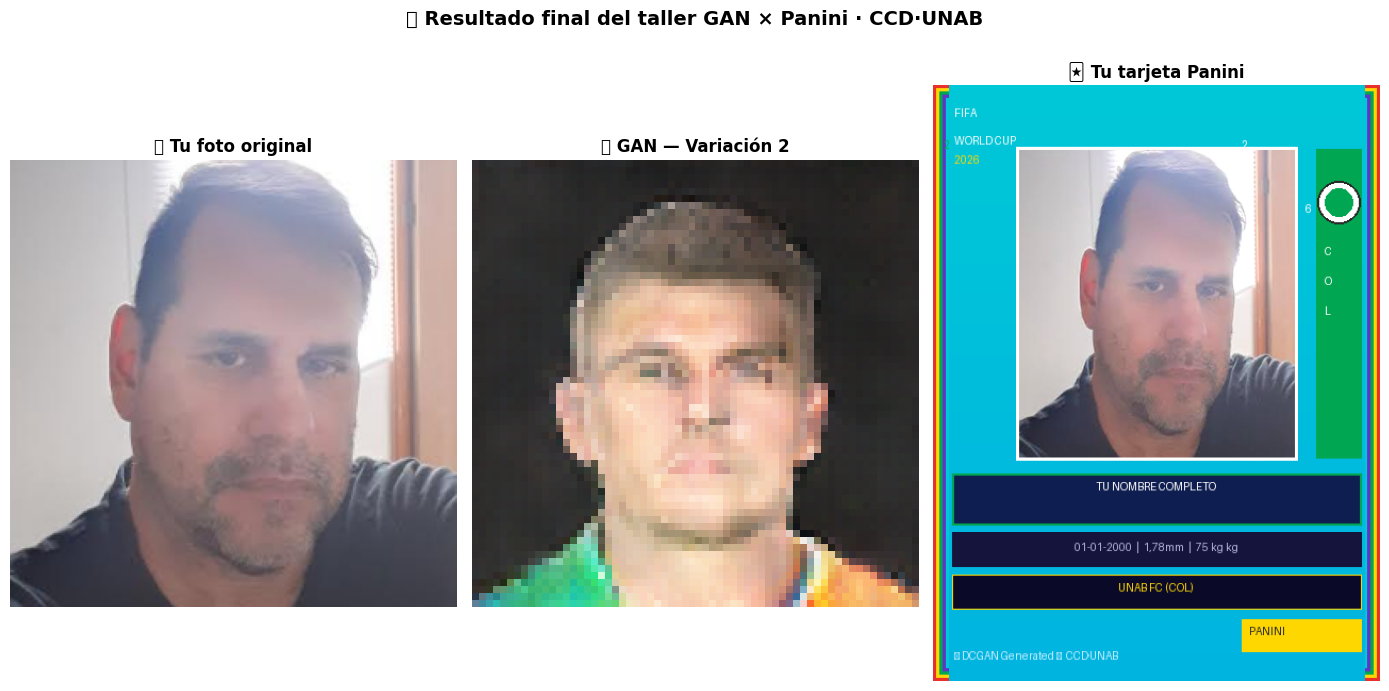

In [ ]:
# ── Comparación final: Foto real vs GAN vs Tarjeta ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 7))

axes[0].imshow(foto_pil)
axes[0].set_title("📷 Tu foto original", fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(img_futbolista_pil)
axes[1].set_title(f"🤖 GAN — Variación {VARIACION_ELEGIDA}", fontsize=12, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(mi_tarjeta)
axes[2].set_title("🃏 Tu tarjeta Panini", fontsize=12, fontweight='bold')
axes[2].axis('off')

plt.suptitle("✨ Resultado final del taller GAN × Panini · CCD·UNAB",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
# ── Descargar la tarjeta Panini ──────────────────────────────────────────────

# Guardar en alta resolución
nombre_archivo = f"tarjeta_panini_{MI_NOMBRE.replace(' ', '_')}.png"
mi_tarjeta_hd = mi_tarjeta.resize(
    (mi_tarjeta.width * 3, mi_tarjeta.height * 3),
    Image.LANCZOS
)
mi_tarjeta_hd.save(nombre_archivo, dpi=(300, 300))
files.download(nombre_archivo)
print(f"✅ Tarjeta descargada: {nombre_archivo}")
print(f"   Resolución: {mi_tarjeta_hd.size[0]}x{mi_tarjeta_hd.size[1]} px @ 300 DPI")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Tarjeta descargada: tarjeta_panini_TU_NOMBRE_COMPLETO.png
   Resolución: 1260x1680 px @ 300 DPI


---
## 🧩 Paso 8: Preguntas de reflexión

Responde en la siguiente celda de texto (doble clic para editar):

1. **¿Qué diferencias visuales observas** entre las imágenes generadas en la época 1 y la época final?

2. **¿Qué sucede** si cambias la tasa de aprendizaje a `1e-3`? ¿Y a `1e-6`?

3. **¿Por qué es importante** el Label Smoothing en el entrenamiento de GANs?

4. **¿Qué significa** que el Loss del Generador y el Discriminador oscilen sin converger a 0?

5. **Experimento avanzado:** ¿Qué cambiarías en la arquitectura para generar imágenes de **128x128** px?

---

> 🏆 **¡Felicitaciones!** Completaste el taller de DCGAN × Panini.  
> Acabas de entrenar una red generativa adversaria y crear tu propia tarjeta de futbolista con IA.

**Créditos:** Centro de Competencias Digitales (CCD) · UNAB · Bucaramanga, Colombia


### ✍️ Escribe tus respuestas aquí

**1. Diferencias entre época 1 y época final:**  
*(Tu respuesta)*

**2. Efecto de cambiar la tasa de aprendizaje:**  
*(Tu respuesta)*

**3. Importancia del Label Smoothing:**  
*(Tu respuesta)*

**4. Oscilación de pérdidas:**  
*(Tu respuesta)*

**5. Experimento para 128x128:**  
*(Tu respuesta)*
